# Étape 6 : Comparaison des architectures de deep learning
Objectif : entraîner et comparer huit architectures (M1 à M8) pour classer les fèves de cacao, en mesurant leurs performances, leur complexité et leur temps de calcul.

**Protocole commun :** apprentissage sur les plis 1 à 4, validation sur le pli 0 (arrêt précoce), évaluation sur l'ensemble de test ; augmentation de données intégrée au modèle ; poids de classe pour compenser le déséquilibre ; 3 graines par modèle (moyenne ± écart-type). Exécution sur Google Colab (GPU T4).

In [ ]:
# GPU et Google Drive
import tensorflow as tf
print("TensorFlow", tf.__version__, "| GPU :", tf.config.list_physical_devices("GPU"))

from google.colab import drive
drive.mount("/content/drive")

import os
os.chdir("/content/drive/MyDrive/cocoa-bean-classification")
os.makedirs("results/dl", exist_ok=True)
os.makedirs("models", exist_ok=True)
print("Dossier de travail :", os.getcwd(), "|", os.listdir("."))

TensorFlow 2.21.0 | GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive
Dossier de travail : /content/drive/MyDrive/cocoa-bean-classification | ['data', 'results', 'models', '06_deep_learning.ipynb']


In [ ]:
# données et découpage

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, cohen_kappa_score, roc_auc_score, confusion_matrix)

donnees = np.load("data/donnees_feves.npz")
X = donnees["X"].astype("float32")        # pixels de 0 à 255 : chaque modèle gère sa normalisation
y = donnees["y"]
df = pd.read_csv("results/02_decoupage.csv")
classes = ["category 1", "category 2", "category 3"]

idx_app = np.where((df["partition"] == "train") & (df["pli"] != 0))[0]   # apprentissage
idx_val = np.where(df["pli"] == 0)[0]                                    # validation (arrêt précoce)
idx_test = np.where(df["partition"] == "test")[0]
print(f"Apprentissage : {len(idx_app)} | Validation : {len(idx_val)} | Test : {len(idx_test)}")

poids = compute_class_weight("balanced", classes=np.arange(3), y=y[idx_app])
poids_classes = dict(enumerate(poids))
print("Poids des classes :", {classes[k]: round(v, 2) for k, v in poids_classes.items()})

Apprentissage : 2861 | Validation : 715 | Test : 894
Poids des classes : {'category 1': np.float64(0.78), 'category 2': np.float64(0.89), 'category 3': np.float64(1.7)}


In [ ]:
# l’augmentation et l’évaluation (communes à tous les modèles)

def bloc_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.25, fill_mode="nearest"),
        layers.RandomTranslation(0.1, 0.1, fill_mode="nearest"),
        layers.RandomBrightness(0.1, value_range=(0, 255)),
    ], name="augmentation")

def evaluer(y_vrai, proba):
    """Toutes les métriques du sujet, à partir des probabilités prédites."""
    pred = proba.argmax(axis=1)
    return {
        "Accuracy": accuracy_score(y_vrai, pred),
        "Precision (macro)": precision_score(y_vrai, pred, average="macro"),
        "Recall (macro)": recall_score(y_vrai, pred, average="macro"),
        "F1 (macro)": f1_score(y_vrai, pred, average="macro"),
        "MCC": matthews_corrcoef(y_vrai, pred),
        "Kappa": cohen_kappa_score(y_vrai, pred),
        "ROC-AUC": roc_auc_score(y_vrai, proba, multi_class="ovr", average="macro"),
    }

In [ ]:
# la fonction d’entraînement

def entrainer(construire_modele, nom, graine=42, epochs=80, lr=1e-3, batch=64):
    keras.utils.set_random_seed(graine)          # rend l'entraînement reproductible
    modele = construire_modele()
    modele.compile(optimizer=keras.optimizers.Adam(lr),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    rappels = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4),
    ]
    debut = time.time()
    historique = modele.fit(X[idx_app], y[idx_app], validation_data=(X[idx_val], y[idx_val]),
                            epochs=epochs, batch_size=batch, class_weight=poids_classes,
                            callbacks=rappels, verbose=0)
    duree = time.time() - debut

    debut = time.time()
    proba = modele.predict(X[idx_test], verbose=0)
    temps_inference = (time.time() - debut) / len(idx_test) * 1000     # ms par image

    resultat = {"Modèle": nom, "Graine": graine, **evaluer(y[idx_test], proba),
                "Paramètres": modele.count_params(), "Époques": len(historique.history["loss"]),
                "Temps d'entraînement (s)": duree, "Inférence (ms/image)": temps_inference}
    return modele, historique.history, proba, resultat

In [ ]:
# construction de M1 (M1 : le CNN classique)


def construire_cnn():
    entree = keras.Input(shape=(60, 60, 3))
    x = bloc_augmentation()(entree)
    x = layers.Rescaling(1 / 255)(x)
    for filtres in [32, 64, 128]:
        for _ in range(2):
            x = layers.Conv2D(filtres, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)                 # 60 -> 30 -> 15 -> 7
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    sortie = layers.Dense(3, activation="softmax")(x)
    return keras.Model(entree, sortie, name="M1_CNN")

construire_cnn().summary()

Model: "M1_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 60, 60, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 60, 60, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 60, 60, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 60, 60, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 60, 60, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_27 (Activation)      │ (None, 60, 60, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 60, 60, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 60, 60, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_28 (Activation)      │ (None, 60, 60, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 30, 30, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_26          │ (None, 30, 30, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_29 (Activation)      │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 30, 30, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 30, 30, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_30 (Activation)      │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 15, 15, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 15, 15, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_31 (Activation)      │ (None, 15, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 15, 15, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 15, 15, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 288,739 (1.10 MB)

 Trainable params: 287,843 (1.10 MB)

 Non-trainable params: 896 (3.50 KB)

{'Modèle': 'M1 – CNN classique', 'Graine': 42, 'Accuracy': 0.9329, 'Precision (macro)': 0.9443, 'Recall (macro)': 0.9455, 'F1 (macro)': 0.9442, 'MCC': np.float64(0.8959), 'Kappa': np.float64(0.8949), 'ROC-AUC': np.float64(0.9871), 'Paramètres': 288739, 'Époques': 71, "Temps d'entraînement (s)": 176.7918, 'Inférence (ms/image)': 1.7331}


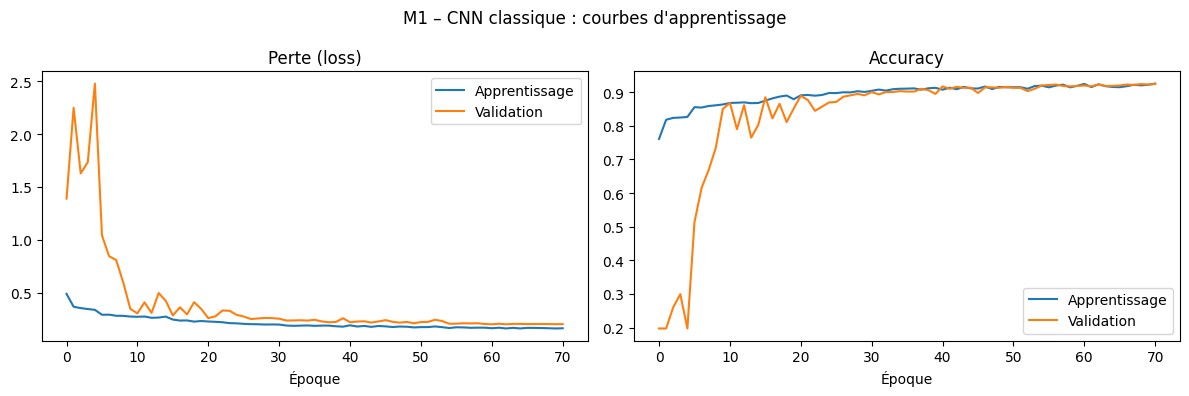

In [ ]:
# 1er  entraînement et courbes d’apprentissage

modele_m1, hist_m1, proba_m1, res_m1 = entrainer(construire_cnn, "M1 – CNN classique", graine=42)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in res_m1.items()})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_m1["loss"], label="Apprentissage"); axes[0].plot(hist_m1["val_loss"], label="Validation")
axes[0].set_title("Perte (loss)"); axes[0].set_xlabel("Époque"); axes[0].legend()
axes[1].plot(hist_m1["accuracy"], label="Apprentissage"); axes[1].plot(hist_m1["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Époque"); axes[1].legend()
plt.suptitle("M1 – CNN classique : courbes d'apprentissage")
plt.tight_layout()
plt.savefig("results/dl/06_courbes_M1.png", dpi=150)
plt.show()

**M1 – CNN classique :** F1 macro de 94,4 % sur le test (ROC-AUC 98,7 %), avec 289 000 paramètres et 3 minutes d'entraînement. Les courbes montrent une validation instable pendant les dix premières époques (stabilisation de la normalisation par lots), puis une convergence sans sur-apprentissage : les courbes d'apprentissage et de validation restent superposées. Ce CNN entraîné depuis zéro reste en dessous du meilleur SVM sur caractéristiques (98,1 %) : avec moins de 3 000 images de 60 × 60 pixels, il doit apprendre seul ce que les caractéristiques manuelles apportaient déjà (couleur corrigée, fève isolée, texture).

In [ ]:
# conservation les résultats au fur et à mesure

tous_resultats = [res_m1]
historiques = {"M1": hist_m1}

def sauvegarder_resultats():
    pd.DataFrame(tous_resultats).to_csv("results/dl/06_resultats_modeles.csv", index=False)

sauvegarder_resultats()

In [ ]:
# construction des modèles pré-entraînés

TAILLE = 128

def construire_transfert(nom_base):
    if nom_base == "ResNet50":
        base = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(TAILLE, TAILLE, 3))
        pretraitement = keras.applications.resnet50.preprocess_input
    else:
        base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(TAILLE, TAILLE, 3))
        pretraitement = keras.applications.efficientnet.preprocess_input
    base.trainable = False                          # phase 1 : réseau pré-entraîné gelé

    entree = keras.Input(shape=(60, 60, 3))
    x = bloc_augmentation()(entree)
    x = layers.Resizing(TAILLE, TAILLE)(x)
    x = pretraitement(x)                            # normalisation propre à chaque réseau
    x = base(x, training=False)                     # BatchNorm du réseau pré-entraîné en mode « figé »
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    sortie = layers.Dense(3, activation="softmax")(x)
    return keras.Model(entree, sortie, name=nom_base), base

In [ ]:
# entraînement en deux phases

def entrainer_transfert(nom_base, nom, graine=42, couches_ouvertes=30):
    keras.utils.set_random_seed(graine)
    modele, base = construire_transfert(nom_base)
    donnees_fit = dict(x=X[idx_app], y=y[idx_app], validation_data=(X[idx_val], y[idx_val]),
                       batch_size=64, class_weight=poids_classes, verbose=0)
    debut = time.time()

    # Phase 1 : extraction de caractéristiques (base gelée)
    modele.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h1 = modele.fit(epochs=30, callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                                                         restore_best_weights=True)], **donnees_fit)
    # NOUVEAU : on mémorise le meilleur état de la phase 1
    meilleure_perte_phase1 = min(h1.history["val_loss"])
    poids_phase1 = modele.get_weights()

    # Phase 2 : fine-tuning des dernières couches
    base.trainable = True
    for couche in base.layers[:-couches_ouvertes]:
        couche.trainable = False
    # NOUVEAU : les BatchNorm restent gelées (sinon elles se dérèglent sur nos petits lots)
    for couche in base.layers:
        if isinstance(couche, layers.BatchNormalization):
            couche.trainable = False

    modele.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h2 = modele.fit(epochs=40, callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4)], **donnees_fit)

    # NOUVEAU : si le fine-tuning n'a pas amélioré la validation, on revient à la phase 1
    phase_retenue = 2
    if min(h2.history["val_loss"]) > meilleure_perte_phase1:
        modele.set_weights(poids_phase1)
        phase_retenue = 1
    duree = time.time() - debut

    historique = {k: h1.history[k] + h2.history[k] for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}
    debut = time.time()
    proba = modele.predict(X[idx_test], verbose=0)
    temps_inference = (time.time() - debut) / len(idx_test) * 1000

    resultat = {"Modèle": nom, "Graine": graine, **evaluer(y[idx_test], proba),
                "Paramètres": modele.count_params(), "Époques": len(historique["loss"]),
                "Temps d'entraînement (s)": duree, "Inférence (ms/image)": temps_inference,
                "Phase retenue": phase_retenue}
    return modele, historique, proba, resultat, len(h1.history["loss"])

M2 – ResNet50 : F1 = 0.9692 | 23,593,859 paramètres | 427 s


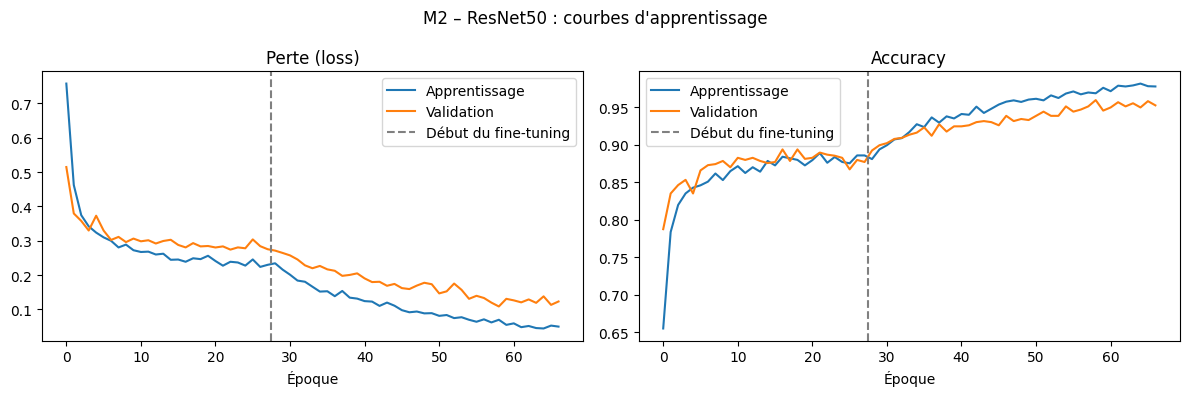

M3 – EfficientNet-B0 : F1 = 0.9071 | 4,053,414 paramètres | 226 s


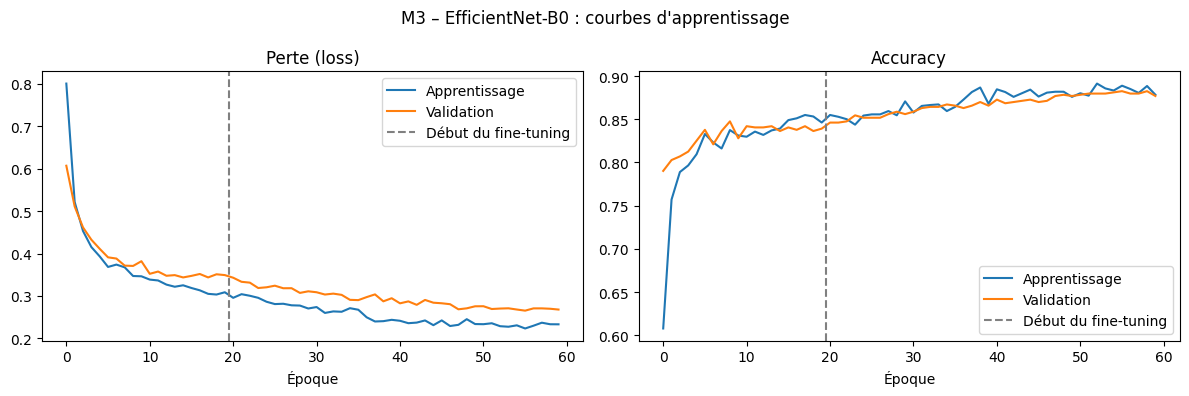

In [ ]:
# entraîner M2 et M3, puis tracer leurs courbes

modeles_transfert = {}
for code, nom_base, nom in [("M2", "ResNet50", "M2 – ResNet50"), ("M3", "EfficientNetB0", "M3 – EfficientNet-B0")]:
    modele, hist, proba, res, fin_phase1 = entrainer_transfert(nom_base, nom)
    modeles_transfert[code] = (modele, proba)
    historiques[code] = hist
    tous_resultats.append(res)
    sauvegarder_resultats()
    duree = res["Temps d'entraînement (s)"]
    print(f"{nom} : F1 = {res['F1 (macro)']:.4f} | {res['Paramètres']:,} paramètres | {duree:.0f} s")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, cle, titre in [(axes[0], "loss", "Perte (loss)"), (axes[1], "accuracy", "Accuracy")]:
        ax.plot(hist[cle], label="Apprentissage")
        ax.plot(hist["val_" + cle], label="Validation")
        ax.axvline(fin_phase1 - 0.5, color="gray", linestyle="--", label="Début du fine-tuning")
        ax.set_title(titre); ax.set_xlabel("Époque"); ax.legend()
    plt.suptitle(f"{nom} : courbes d'apprentissage")
    plt.tight_layout()
    plt.savefig(f"results/dl/06_courbes_{code}.png", dpi=150)
    plt.show()

**M2 – ResNet50 et M3 – EfficientNet-B0 (transfert d'apprentissage) :**
- Stratégie en deux phases : extraction de caractéristiques (base gelée, taux 10⁻³), puis fine-tuning des 30 dernières couches (taux 10⁻⁵), en conservant la meilleure des deux phases.
- **Difficulté rencontrée :** lors d'un premier essai, la perte bondissait au début du fine-tuning et EfficientNet chutait à 83,4 %. Cause : avec Keras 3, les couches BatchNorm dégelées recalculaient leurs statistiques sur nos petits lots malgré `training=False`. Les geler explicitement a supprimé le problème (EfficientNet : 83,4 → 90,7 %).
- **ResNet50** atteint 96,9 % : le fine-tuning apporte un gain net (validation 88 → 95 %), avec un léger sur-apprentissage en fin d'entraînement.
- **EfficientNet-B0** (90,7 %) reste en dessous du CNN classique : ses caractéristiques ImageNet semblent moins transférables à des images de 60 × 60 pixels floues et agrandies. Il était encore en progression à la limite de 40 époques.

In [ ]:
#Briques communes

def conv_bn_relu(x, filtres, taille=3, dilatation=1):
    x = layers.Conv2D(filtres, taille, padding="same", dilation_rate=dilatation, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation("relu")(x)

def extracteur_cnn(x):
    """Le CNN de M1 sans sa tête de classification : 60x60x3 -> 7x7x128."""
    for filtres in [32, 64, 128]:
        x = conv_bn_relu(x, filtres)
        x = conv_bn_relu(x, filtres)
        x = layers.MaxPooling2D()(x)
    return x

class AjoutPosition(layers.Layer):
    """Ajoute à chaque token un vecteur de position appris."""
    def build(self, forme):
        self.positions = self.add_weight(shape=(1, forme[1], forme[2]),
                                         initializer="random_normal", name="positions")
    def call(self, x):
        return x + self.positions

def bloc_transformer(x, tetes=4, dim=128, dim_mlp=256, dropout=0.1):
    # 1) Attention : chaque zone regarde toutes les autres
    y = layers.LayerNormalization()(x)
    y = layers.MultiHeadAttention(num_heads=tetes, key_dim=dim // tetes, dropout=dropout)(y, y)
    x = layers.Add()([x, y])                         # connexion résiduelle
    # 2) Petit réseau dense appliqué à chaque zone
    y = layers.LayerNormalization()(x)
    y = layers.Dense(dim_mlp, activation="gelu")(y)
    y = layers.Dropout(dropout)(y)
    y = layers.Dense(dim)(y)
    return layers.Add()([x, y])                      # connexion résiduelle

def tracer_courbes(hist, code, nom, fin_phase1=None):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, cle, titre in [(axes[0], "loss", "Perte (loss)"), (axes[1], "accuracy", "Accuracy")]:
        ax.plot(hist[cle], label="Apprentissage")
        ax.plot(hist["val_" + cle], label="Validation")
        if fin_phase1:
            ax.axvline(fin_phase1 - 0.5, color="gray", linestyle="--", label="Début du fine-tuning")
        ax.set_title(titre); ax.set_xlabel("Époque"); ax.legend()
    plt.suptitle(f"{nom} : courbes d'apprentissage")
    plt.tight_layout()
    plt.savefig(f"results/dl/06_courbes_{code}.png", dpi=150)
    plt.show()

In [ ]:
# M4 et M5

def bloc_multi_echelle(x, filtres):
    b3 = conv_bn_relu(x, filtres, 3)                   # détails fins
    b5 = conv_bn_relu(x, filtres, 5)                   # structures intermédiaires
    b7 = conv_bn_relu(x, filtres, 3, dilatation=3)     # structures globales (champ 7x7)
    x = layers.Concatenate()([b3, b5, b7])
    x = conv_bn_relu(x, filtres * 2, 1)                # fusion des trois échelles
    return layers.MaxPooling2D()(x)

def construire_multi_echelle():
    entree = keras.Input(shape=(60, 60, 3))
    x = bloc_augmentation()(entree)
    x = layers.Rescaling(1 / 255)(x)
    x = conv_bn_relu(x, 32)
    for filtres in [32, 64, 64]:
        x = bloc_multi_echelle(x, filtres)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    return keras.Model(entree, layers.Dense(3, activation="softmax")(x), name="M4_Multi_echelle")

def construire_cnn_transformer():
    entree = keras.Input(shape=(60, 60, 3))
    x = bloc_augmentation()(entree)
    x = layers.Rescaling(1 / 255)(x)
    x = extracteur_cnn(x)                    # (7, 7, 128)
    x = layers.Reshape((-1, 128))(x)         # 49 tokens de dimension 128
    x = AjoutPosition()(x)
    for _ in range(2):
        x = bloc_transformer(x)
    x = layers.LayerNormalization()(x)
    x = layers.GlobalAveragePooling1D()(x)   # moyenne des 49 tokens
    x = layers.Dropout(0.3)(x)
    return keras.Model(entree, layers.Dense(3, activation="softmax")(x), name="M5_CNN_Transformer")

M4 – CNN multi-échelle : F1 = 0.9497 | 632,291 paramètres | 359 s


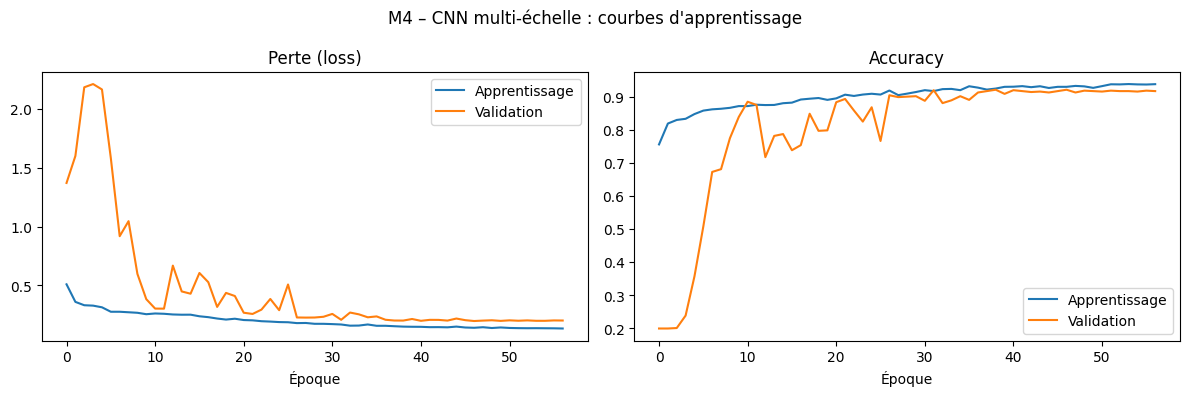

M5 – CNN + Transformer : F1 = 0.9651 | 560,227 paramètres | 179 s


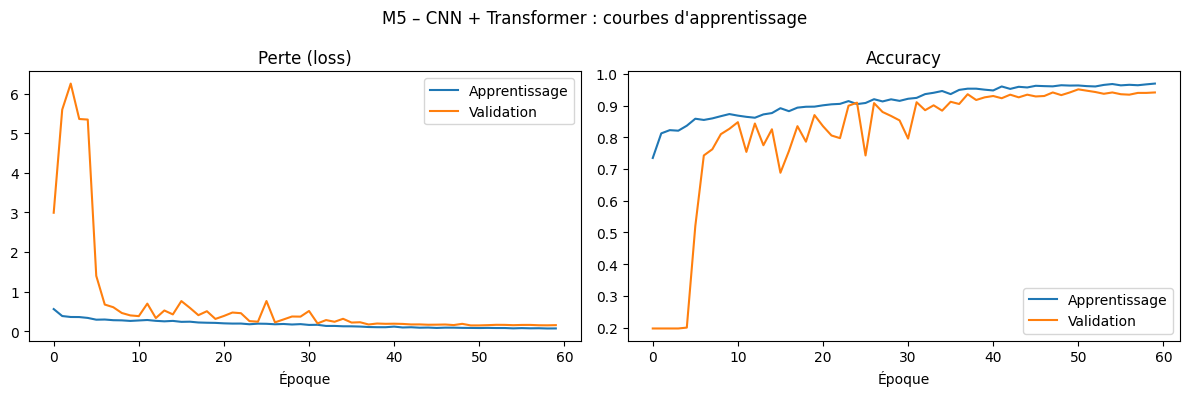

In [ ]:
# Entraîner M4 et M5

for code, construire, nom in [("M4", construire_multi_echelle, "M4 – CNN multi-échelle"),
                              ("M5", construire_cnn_transformer, "M5 – CNN + Transformer")]:
    modele, hist, proba, res = entrainer(construire, nom, graine=42)
    historiques[code] = hist
    tous_resultats.append(res)
    sauvegarder_resultats()
    duree = res["Temps d'entraînement (s)"]
    print(f"{nom} : F1 = {res['F1 (macro)']:.4f} | {res['Paramètres']:,} paramètres | {duree:.0f} s")
    tracer_courbes(hist, code, nom)

In [ ]:
# les paires de fèves

import tensorflow as tf
from keras import ops

X_tf = tf.constant(X)      # toutes les images, accessibles rapidement par leur numéro

def generer_paires(indices, nb_paires, graine):
    """Moitié de paires de même catégorie (étiquette 1), moitié de catégories différentes (0)."""
    rng = np.random.default_rng(graine)
    par_classe = {c: indices[y[indices] == c] for c in range(3)}
    a, b, meme = [], [], []
    for _ in range(nb_paires):
        c = rng.integers(3)
        i = rng.choice(par_classe[c])
        if rng.random() < 0.5:
            j, s = rng.choice(par_classe[c]), 1
        else:
            autre = rng.choice([k for k in range(3) if k != c])
            j, s = rng.choice(par_classe[autre]), 0
        a.append(i); b.append(j); meme.append(s)
    return np.array(a), np.array(b), np.array(meme, dtype="float32")

def jeu_paires(indices, nb_paires, graine, melanger=True):
    a, b, s = generer_paires(indices, nb_paires, graine)
    ds = tf.data.Dataset.from_tensor_slices((a, b, s))
    if melanger:
        ds = ds.shuffle(len(a), seed=graine)
    ds = ds.map(lambda i, j, l: ((tf.gather(X_tf, i), tf.gather(X_tf, j)), l))
    return ds.batch(64).prefetch(tf.data.AUTOTUNE)

In [ ]:
# Les encodeurs, la distance et la perte contrastive

def encodeur_cnn(dim=64):
    entree = keras.Input(shape=(60, 60, 3))
    x = bloc_augmentation()(entree)
    x = layers.Rescaling(1 / 255)(x)
    x = extracteur_cnn(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(dim)(x)
    x = layers.UnitNormalization()(x)            # chaque plongement a une longueur de 1
    return keras.Model(entree, x, name="encodeur_CNN")

def encodeur_cnn_transformer(dim=64):
    entree = keras.Input(shape=(60, 60, 3))
    x = bloc_augmentation()(entree)
    x = layers.Rescaling(1 / 255)(x)
    x = extracteur_cnn(x)
    x = layers.Reshape((-1, 128))(x)
    x = AjoutPosition()(x)
    for _ in range(2):
        x = bloc_transformer(x)
    x = layers.LayerNormalization()(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(dim)(x)
    x = layers.UnitNormalization()(x)
    return keras.Model(entree, x, name="encodeur_CNN_Transformer")

class Distance(layers.Layer):
    """Distance euclidienne entre deux plongements."""
    def call(self, ea, eb):
        return ops.sqrt(ops.sum(ops.square(ea - eb), axis=1, keepdims=True) + 1e-9)

def perte_contrastive(marge=1.0):
    def perte(meme, d):
        meme = ops.reshape(meme, (-1, 1))
        rapprocher = meme * ops.square(d)                                   # même catégorie : d -> 0
        eloigner = (1 - meme) * ops.square(ops.maximum(marge - d, 0))       # sinon : d >= marge
        return ops.mean(rapprocher + eloigner)
    return perte

def construire_siamois(construire_encodeur):
    encodeur = construire_encodeur()                 # UN seul encodeur...
    a = keras.Input(shape=(60, 60, 3))
    b = keras.Input(shape=(60, 60, 3))
    d = Distance()(encodeur(a), encodeur(b))         # ... utilisé pour les deux branches
    return keras.Model([a, b], d), encodeur

In [ ]:
# entraînement et classification par prototypes

def entrainer_siamois(construire_encodeur, nom, graine=42, epochs=80):
    keras.utils.set_random_seed(graine)
    siamois, encodeur = construire_siamois(construire_encodeur)
    siamois.compile(optimizer=keras.optimizers.Adam(1e-3), loss=perte_contrastive())
    debut = time.time()
    h = siamois.fit(jeu_paires(idx_app, 10000, graine),
                    validation_data=jeu_paires(idx_val, 2000, graine + 1, melanger=False),
                    epochs=epochs, verbose=0,
                    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
                               keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4)])
    duree = time.time() - debut

    # Prototypes : plongement moyen de chaque catégorie (fèves d'apprentissage)
    emb_app = encodeur.predict(X[idx_app], verbose=0)
    prototypes = np.array([emb_app[y[idx_app] == c].mean(axis=0) for c in range(3)])
    prototypes /= np.linalg.norm(prototypes, axis=1, keepdims=True)

    debut = time.time()
    emb_test = encodeur.predict(X[idx_test], verbose=0)
    distances = np.linalg.norm(emb_test[:, None, :] - prototypes[None, :, :], axis=2)
    temps_inference = (time.time() - debut) / len(idx_test) * 1000

    # Probabilités : plus une fève est proche d'un prototype, plus la probabilité est forte
    proba = np.exp(-5 * distances)
    proba /= proba.sum(axis=1, keepdims=True)

    resultat = {"Modèle": nom, "Graine": graine, **evaluer(y[idx_test], proba),
                "Paramètres": encodeur.count_params(), "Époques": len(h.history["loss"]),
                "Temps d'entraînement (s)": duree, "Inférence (ms/image)": temps_inference}
    return encodeur, h.history, proba, resultat, emb_test

M6 – Siamese CNN : F1 = 0.9431 | 296,608 paramètres | 1163 s


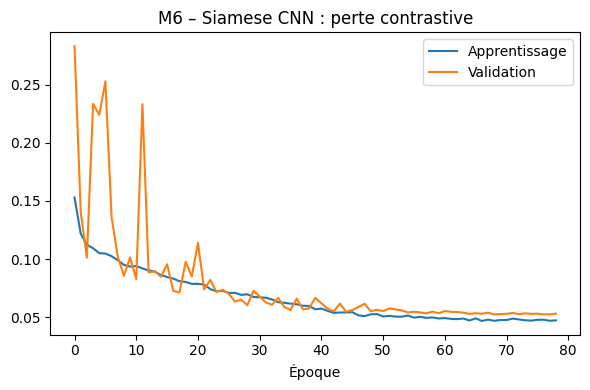

M7 – Siamese CNN-Transformer : F1 = 0.9627 | 568,096 paramètres | 1089 s


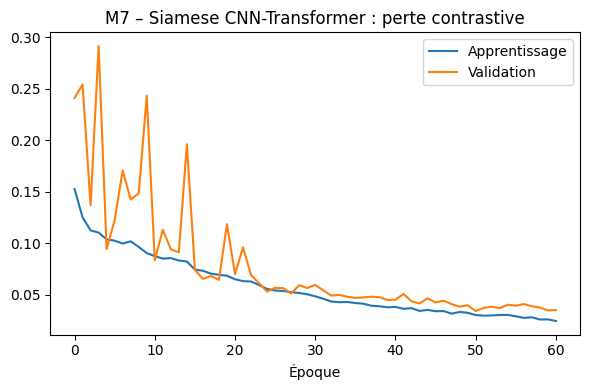

In [ ]:
# Entraîner M6 et M7

plongements = {}
for code, construire, nom in [("M6", encodeur_cnn, "M6 – Siamese CNN"),
                              ("M7", encodeur_cnn_transformer, "M7 – Siamese CNN-Transformer")]:
    encodeur, hist, proba, res, emb_test = entrainer_siamois(construire, nom)
    plongements[code] = emb_test
    tous_resultats.append(res)
    sauvegarder_resultats()
    duree = res["Temps d'entraînement (s)"]
    print(f"{nom} : F1 = {res['F1 (macro)']:.4f} | {res['Paramètres']:,} paramètres | {duree:.0f} s")

    plt.figure(figsize=(6, 4))
    plt.plot(hist["loss"], label="Apprentissage"); plt.plot(hist["val_loss"], label="Validation")
    plt.title(f"{nom} : perte contrastive"); plt.xlabel("Époque"); plt.legend()
    plt.tight_layout(); plt.savefig(f"results/dl/06_courbes_{code}.png", dpi=150); plt.show()

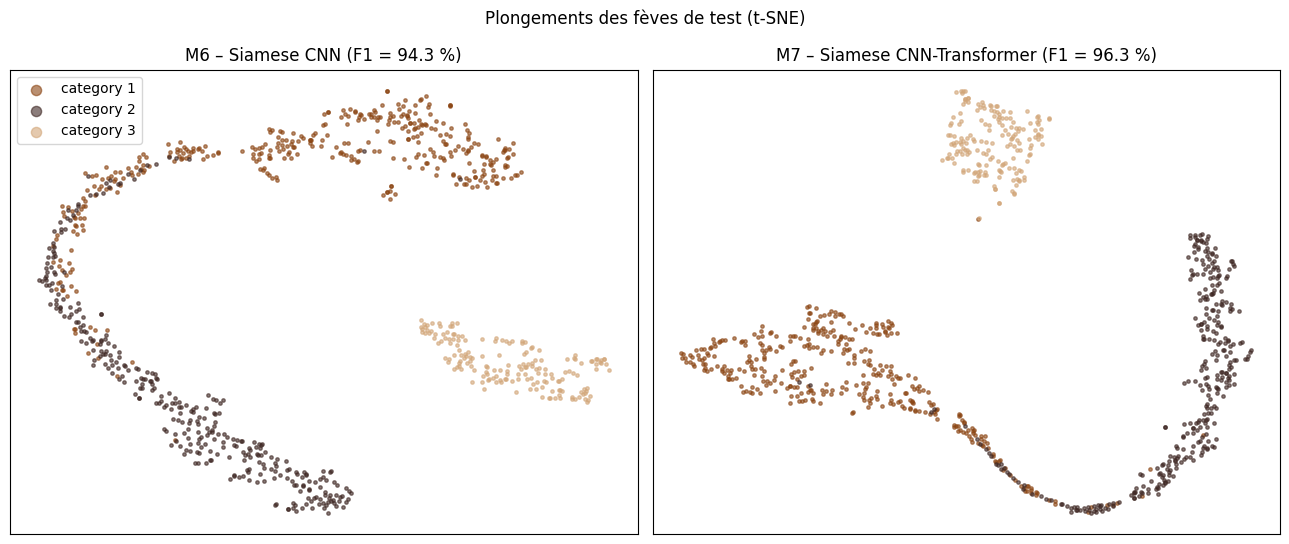

In [ ]:
# Visualiser les plongements avec t-SNE

from sklearn.manifold import TSNE

couleurs_classes = ["#8B4513", "#3E2723", "#D2A679"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (code, nom) in zip(axes, [("M6", "M6 – Siamese CNN"), ("M7", "M7 – Siamese CNN-Transformer")]):
    Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(plongements[code])
    for c in range(3):
        sel = y[idx_test] == c
        ax.scatter(Z[sel, 0], Z[sel, 1], s=6, alpha=0.6, color=couleurs_classes[c], label=classes[c])
    ax.set_title(f"{nom} (F1 = {[r for r in tous_resultats if r['Modèle'] == nom][0]['F1 (macro)'] * 100:.1f} %)")
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=3)
plt.suptitle("Plongements des fèves de test (t-SNE)")
plt.tight_layout()
plt.savefig("results/dl/06_tsne_siamois.png", dpi=150)
plt.show()

**M6 – Siamese CNN et M7 – Siamese CNN-Transformer :** les réseaux siamois apprennent une distance entre fèves (perte contrastive, marge 1) à partir de 10 000 paires par époque ; la classification se fait par le prototype le plus proche.
- **M6** (94,3 %) égale le CNN classique M1 (94,4 %), avec lequel il partage son encodeur.
- **M7** (96,3 %) gagne 2 points grâce à l'encodeur CNN + Transformer, ce qui confirme l'apport de l'attention.
- **Coût :** l'apprentissage par paires est beaucoup plus long (≈ 19 minutes contre 3 pour M1), pour un gain nul (M6) ou modeste (M7).
- **Projection t-SNE des plongements de test :** la Category 3 forme un nuage totalement isolé pour les deux modèles. Avec M6, les Categories 1 et 2 s'alignent sur un arc continu avec une large zone de mélange ; avec M7, elles forment deux nuages distincts reliés par un mince « pont » où se concentrent les fèves ambiguës. M7 resserre donc chaque catégorie et réduit la zone de confusion. Ces projections suggèrent qu'il existe une transition progressive, et non une frontière nette, entre les Categories 1 et 2.

In [ ]:
# Rechargons les résultats déjà sauvegardés sur le Drive
tous_resultats = pd.read_csv("results/dl/06_resultats_modeles.csv").to_dict("records")
historiques = {}

def sauvegarder_resultats():
    pd.DataFrame(tous_resultats).to_csv("results/dl/06_resultats_modeles.csv", index=False)

for r in tous_resultats:
    print(f"{r['Modèle']:35s} F1 = {r['F1 (macro)']:.4f}")

M1 – CNN classique                  F1 = 0.9442
M2 – ResNet50                       F1 = 0.9692
M3 – EfficientNet-B0                F1 = 0.9071
M4 – CNN multi-échelle              F1 = 0.9506
M5 – CNN + Transformer              F1 = 0.9530
M6 – Siamese CNN                    F1 = 0.9431
M7 – Siamese CNN-Transformer        F1 = 0.9627


In [ ]:
#la couche ANFIS

class CoucheANFIS(layers.Layer):
    """Système d'inférence neuro-flou de Takagi-Sugeno (premier ordre)."""

    def __init__(self, nb_regles=12, nb_sorties=3, **kwargs):
        super().__init__(**kwargs)
        self.nb_regles = nb_regles
        self.nb_sorties = nb_sorties

    def build(self, forme):
        d = forme[-1]                                          # nombre d'entrées floues
        # Couche 1 : un centre et une largeur par règle et par entrée
        self.centres = self.add_weight(shape=(self.nb_regles, d), initializer="random_normal", name="centres")
        self.log_sigmas = self.add_weight(shape=(self.nb_regles, d), initializer="zeros", name="log_sigmas")
        # Couche 4 : conséquents linéaires y = A.x + b pour chaque règle
        self.A = self.add_weight(shape=(self.nb_regles, d, self.nb_sorties), initializer="glorot_uniform", name="A")
        self.b = self.add_weight(shape=(self.nb_regles, self.nb_sorties), initializer="zeros", name="b")

    def forces(self, x):
        """Couches 1 à 3 : force normalisée de chaque règle, forme (lot, nb_regles)."""
        ecart = (ops.expand_dims(x, 1) - self.centres) / ops.exp(self.log_sigmas)
        exposant = -0.5 * ops.sum(ops.square(ecart), axis=-1)  # log du produit des gaussiennes
        return ops.softmax(exposant, axis=-1)                   # normalisation w / somme(w)

    def call(self, x):
        w = self.forces(x)                                                # couches 1 à 3
        y_regles = ops.einsum("bd,rdk->brk", x, self.A) + self.b         # couche 4
        return ops.sum(ops.expand_dims(w, -1) * y_regles, axis=1)        # couche 5

    def get_config(self):
        config = super().get_config()
        config.update(nb_regles=self.nb_regles, nb_sorties=self.nb_sorties)
        return config

In [ ]:
# Construction de M8

from keras import ops
def construire_cnn_transformer_anfis(nb_entrees_floues=8, nb_regles=12):
    entree = keras.Input(shape=(60, 60, 3))
    x = bloc_augmentation()(entree)
    x = layers.Rescaling(1 / 255)(x)
    x = extracteur_cnn(x)                                   # CNN : caractéristiques locales
    x = layers.Reshape((-1, 128))(x)
    x = AjoutPosition()(x)
    for _ in range(2):
        x = bloc_transformer(x)                             # Transformer : relations entre zones
    x = layers.LayerNormalization()(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(nb_entrees_floues, name="entrees_floues")(x)        # résumé en 8 caractéristiques
    x = layers.BatchNormalization(name="normalisation_floue")(x)          # centrées autour de 0
    x = CoucheANFIS(nb_regles, 3, name="anfis")(x)                        # règles floues
    return keras.Model(entree, layers.Activation("softmax")(x), name="M8_CNN_Transformer_ANFIS")

construire_cnn_transformer_anfis().summary()

Model: "M8_CNN_Transformer_ANFIS"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 60, 60, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 60, 60, 3) │          0 │ input_layer_2[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 60, 60, 3) │          0 │ augmentation[0][… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 60, 60,    │        864 │ rescaling_1[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 60, 60,    │        128 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 60, 60,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 60, 60,    │      9,216 │ activation_6[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 60, 60,    │        128 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_7        │ (None, 60, 60,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 30, 30,    │          0 │ activation_7[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 30, 30,    │     18,432 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 30,    │        256 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 30, 30,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 30, 30,    │     36,864 │ activation_8[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 30,    │        256 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 30, 30,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 15, 15,    │          0 │ activation_9[0][

 Total params: 561,420 (2.14 MB)

 Trainable params: 560,508 (2.14 MB)

 Non-trainable params: 912 (3.56 KB)

M8 : F1 = 0.9333 | 561,420 paramètres | 178 s


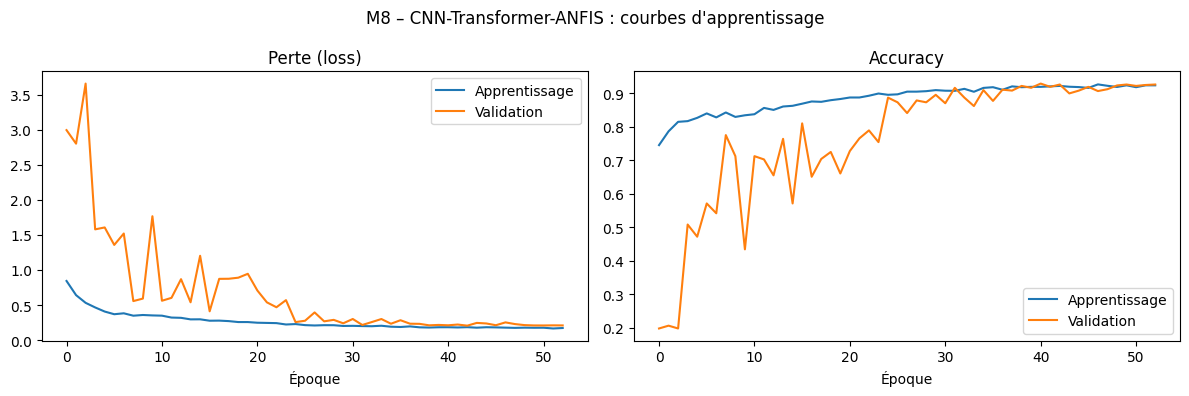

In [ ]:
# Entraînement de M8

modele_m8, hist_m8, proba_m8, res_m8 = entrainer(construire_cnn_transformer_anfis,
                                                 "M8 – CNN-Transformer-ANFIS", graine=42)
historiques["M8"] = hist_m8
tous_resultats.append(res_m8)
sauvegarder_resultats()
duree = res_m8["Temps d'entraînement (s)"]
print(f"M8 : F1 = {res_m8['F1 (macro)']:.4f} | {res_m8['Paramètres']:,} paramètres | {duree:.0f} s")
tracer_courbes(hist_m8, "M8", "M8 – CNN-Transformer-ANFIS")

modele_m8.save("models/M8_CNN_Transformer_ANFIS.keras")

**M8 – CNN-Transformer-ANFIS :** F1 macro de 93,3 % (561 000 paramètres, 3 minutes), légèrement en dessous de M5 (95,3 %), qui partage le même encodeur sans la couche neuro-floue. La validation reste instable pendant environ 25 époques — plus longtemps que pour M5 — car les centres des fonctions d'appartenance, initialisés au hasard, doivent d'abord se positionner, ce qui fait varier brutalement le poids des règles. Les courbes convergent ensuite sans sur-apprentissage. Sur une seule exécution, l'écart avec M5 n'est pas concluant ; l'apport principal attendu de l'ANFIS est l'**interprétabilité** de la décision (règles floues), plutôt qu'un gain de performance.

In [ ]:
# Que font les 12 règles ?

# Entrées floues des fèves de test, puis force de chaque règle
extracteur_flou = keras.Model(modele_m8.input, modele_m8.get_layer("normalisation_floue").output)
entrees_test = extracteur_flou.predict(X[idx_test], verbose=0)
forces = np.array(modele_m8.get_layer("anfis").forces(entrees_test))      # (894, 12)
regle_dominante = forces.argmax(axis=1)

lignes = []
for r in range(forces.shape[1]):
    sel = regle_dominante == r
    lignes.append({
        "Règle": r + 1,
        "Force moyenne": forces[:, r].mean(),
        "Fèves où elle domine": sel.sum(),
        **{f"% {c}": (y[idx_test][sel] == k).mean() * 100 if sel.sum() else np.nan
           for k, c in enumerate(classes)},
    })
df_regles = pd.DataFrame(lignes).round(2)
df_regles.to_csv("results/dl/06_regles_anfis.csv", index=False)
df_regles

,Règle,Force moyenne,Fèves où elle domine,% category 1,% category 2,% category 3
0,1,0.00,0,NaN,NaN,NaN
1,2,0.00,0,NaN,NaN,NaN
2,3,0.00,0,NaN,NaN,NaN
3,4,0.00,0,NaN,NaN,NaN
4,5,0.26,299,6.35,93.65,0.00
5,6,0.06,0,NaN,NaN,NaN
6,7,0.37,420,86.67,13.10,0.24
7,8,0.01,0,NaN,NaN,NaN
8,9,0.00,0,NaN,NaN,NaN
9,10,0.04,0,NaN,NaN,NaN


**Analyse des règles floues :** sur les 12 règles disponibles, l'ANFIS s'est spontanément organisé autour de **3 règles dominantes, une par catégorie** :
- la **règle 11** domine sur 175 fèves de test, toutes de la Category 3 (100 %) ;
- la **règle 5** domine sur 299 fèves, à 93,7 % de la Category 2 ;
- la **règle 7** domine sur 420 fèves, à 86,7 % de la Category 1.
Les erreurs proviennent du recouvrement des règles 5 et 7 (13 % de fèves de la Category 2 captées par la règle de la Category 1), ce qui rejoint la zone de transition observée en t-SNE. Les neuf autres règles ne dominent jamais : deux jouent un rôle secondaire de nuance (force moyenne 0,04 à 0,06), les autres sont inactives. Le nombre de règles (12) est donc surdimensionné, et la décision du modèle peut se résumer en trois règles lisibles — c'est l'apport principal de la couche neuro-floue.

## Comparaison finale sur plusieurs graines
Chaque modèle est entraîné avec 3 graines (42, 7, 2026) et les mêmes réglages, afin d'estimer la variabilité due à l'initialisation et au non-déterminisme du GPU. Les résultats sont présentés sous la forme moyenne ± écart-type.

In [ ]:
necessaires = ["construire_cnn", "construire_transfert", "entrainer_transfert",
               "construire_multi_echelle", "construire_cnn_transformer",
               "generer_paires", "jeu_paires", "encodeur_cnn", "encodeur_cnn_transformer",
               "construire_siamois", "entrainer_siamois", "construire_cnn_transformer_anfis"]
manquantes = [f for f in necessaires if f not in globals()]
print("Fonctions manquantes :", manquantes if manquantes else "aucune, tout est prêt")

Fonctions manquantes : aucune, tout est prêt


In [ ]:
import gc

GRAINES = [42, 7, 2026]
CATALOGUE = {
    "M1 – CNN classique":           lambda g: entrainer(construire_cnn, "M1 – CNN classique", graine=g)[3],
    "M2 – ResNet50":                lambda g: entrainer_transfert("ResNet50", "M2 – ResNet50", graine=g)[3],
    "M3 – EfficientNet-B0":         lambda g: entrainer_transfert("EfficientNetB0", "M3 – EfficientNet-B0", graine=g)[3],
    "M4 – CNN multi-échelle":       lambda g: entrainer(construire_multi_echelle, "M4 – CNN multi-échelle", graine=g)[3],
    "M5 – CNN + Transformer":       lambda g: entrainer(construire_cnn_transformer, "M5 – CNN + Transformer", graine=g)[3],
    "M6 – Siamese CNN":             lambda g: entrainer_siamois(encodeur_cnn, "M6 – Siamese CNN", graine=g)[3],
    "M7 – Siamese CNN-Transformer": lambda g: entrainer_siamois(encodeur_cnn_transformer, "M7 – Siamese CNN-Transformer", graine=g)[3],
    "M8 – CNN-Transformer-ANFIS":   lambda g: entrainer(construire_cnn_transformer_anfis, "M8 – CNN-Transformer-ANFIS", graine=g)[3],
}

debut_total = time.time()
for graine in GRAINES:
    for nom, lancer in CATALOGUE.items():
        deja_fait = {(r["Modèle"], int(r["Graine"])) for r in tous_resultats}
        if (nom, graine) in deja_fait:
            continue                                     # déjà entraîné : on passe
        res = lancer(graine)
        tous_resultats.append(res)
        sauvegarder_resultats()                          # sauvegarde immédiate sur le Drive
        ecoule = (time.time() - debut_total) / 60
        print(f"[{ecoule:5.0f} min] {nom} | graine {graine} | F1 = {res['F1 (macro)']:.4f}")
        keras.backend.clear_session()                    # libère la mémoire du GPU
        gc.collect()

print(f"\nTerminé en {(time.time() - debut_total) / 60:.0f} minutes.")

[    3 min] M1 – CNN classique | graine 7 | F1 = 0.9378
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[   10 min] M2 – ResNet50 | graine 7 | F1 = 0.9748
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[   14 min] M3 – EfficientNet-B0 | graine 7 | F1 = 0.8941
[   23 min] M4 – CNN multi-échelle | graine 7 | F1 = 0.9767
[   25 min] M5 – CNN + Transformer | graine 7 | F1 = 0.9516
[   38 min] M6 – Siamese CNN | graine 7 | F1 = 0.9413
[   52 min] M7 – Siamese CNN-Transformer | graine 7 | F1 = 0.9511
[   56 min] M8 – CNN-Transformer-ANFIS | graine 7 | F1 = 0.9487
[   58 min] M1 – CNN classique | graine 2026 | F1 = 0.9409
[   65 min] M2 – ResNet50 | graine 2026 | F1 = 0.9691
[   68 min] M3 – EfficientNet-B0 | graine 2026 | F1 = 0.9033
[   77 min] M4 – CNN multi-échelle | graine 2026 | F1 = 0.9688
[   80 min] M5 – CNN + Transformer | graine 2026 | F1 = 0.9510
[   92 min] M6 – Siamese CNN | graine 2026 | F1 = 0.9334
[  109 min] M7 – Siamese CNN-Transformer | graine 2026 | F1 = 0.9771
[  

In [3]:
# Reprise sans GPU : analyse uniquement
from google.colab import drive
drive.mount("/content/drive")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.chdir("/content/drive/MyDrive/cocoa-bean-classification")

tous_resultats = pd.read_csv("results/dl/06_resultats_modeles.csv").to_dict("records")
print(len(tous_resultats), "entraînements rechargés")

Mounted at /content/drive
24 entraînements rechargés


In [4]:
# Tableau final, moyenne ± écart-type

df_dl = pd.DataFrame(tous_resultats)
metriques = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "MCC", "Kappa", "ROC-AUC"]

moyennes = df_dl.groupby("Modèle")[metriques].mean() * 100
ecarts = df_dl.groupby("Modèle")[metriques].std() * 100
couts = df_dl.groupby("Modèle")[["Paramètres", "Temps d'entraînement (s)", "Inférence (ms/image)"]].mean()

tableau_dl = moyennes.round(1).astype(str) + " ± " + ecarts.round(1).astype(str)
tableau_dl["Paramètres"] = (couts["Paramètres"] / 1e6).round(2).astype(str) + " M"
tableau_dl["Entraînement (min)"] = (couts["Temps d'entraînement (s)"] / 60).round(1)
tableau_dl["Inférence (ms/image)"] = couts["Inférence (ms/image)"].round(2)
tableau_dl = tableau_dl.loc[moyennes["F1 (macro)"].sort_values(ascending=False).index]

tableau_dl.to_csv("results/dl/06_tableau_final_3_graines.csv")
print("Nombre d'entraînements par modèle :", df_dl.groupby("Modèle").size().to_dict())
tableau_dl

Nombre d'entraînements par modèle : {'M1 – CNN classique': 3, 'M2 – ResNet50': 3, 'M3 – EfficientNet-B0': 3, 'M4 – CNN multi-échelle': 3, 'M5 – CNN + Transformer': 3, 'M6 – Siamese CNN': 3, 'M7 – Siamese CNN-Transformer': 3, 'M8 – CNN-Transformer-ANFIS': 3}


,Accuracy,Precision (macro),Recall (macro),F1 (macro),MCC,Kappa,ROC-AUC,Paramètres,Entraînement (min),Inférence (ms/image)
Modèle,,,,,,,,,,
M2 – ResNet50,96.6 ± 0.4,97.1 ± 0.3,97.1 ± 0.3,97.1 ± 0.3,94.6 ± 0.6,94.6 ± 0.6,99.7 ± 0.1,23.59 M,6.9,6.80
M4 – CNN multi-échelle,95.8 ± 1.7,96.5 ± 1.4,96.5 ± 1.4,96.5 ± 1.4,93.5 ± 2.6,93.5 ± 2.6,99.5 ± 0.4,0.63 M,7.5,1.87
M7 – Siamese CNN-Transformer,95.7 ± 1.6,96.4 ± 1.3,96.3 ± 1.3,96.4 ± 1.3,93.2 ± 2.5,93.2 ± 2.5,98.9 ± 0.6,0.57 M,16.2,0.41
M5 – CNN + Transformer,94.8 ± 0.9,95.6 ± 0.8,95.6 ± 0.8,95.6 ± 0.8,91.9 ± 1.4,91.9 ± 1.4,99.4 ± 0.2,0.56 M,2.8,1.37
M8 – CNN-Transformer-ANFIS,93.3 ± 1.0,94.5 ± 0.8,94.1 ± 0.8,94.3 ± 0.8,89.5 ± 1.6,89.5 ± 1.6,98.8 ± 0.3,0.56 M,3.2,1.78
M1 – CNN classique,93.0 ± 0.3,94.2 ± 0.2,94.2 ± 0.4,94.1 ± 0.3,89.1 ± 0.5,89.0 ± 0.5,98.7 ± 0.0,0.29 M,2.7,1.34
M6 – Siamese CNN,92.7 ± 0.6,93.9 ± 0.5,93.9 ± 0.5,93.9 ± 0.5,88.6 ± 0.9,88.6 ± 0.9,98.6 ± 0.3,0.3 M,14.9,0.36
M3 – EfficientNet-B0,88.6 ± 0.7,90.6 ± 0.6,90.2 ± 0.6,90.2 ± 0.7,82.4 ± 1.0,82.0 ± 1.1,97.3 ± 0.1,4.05 M,3.7,6.60


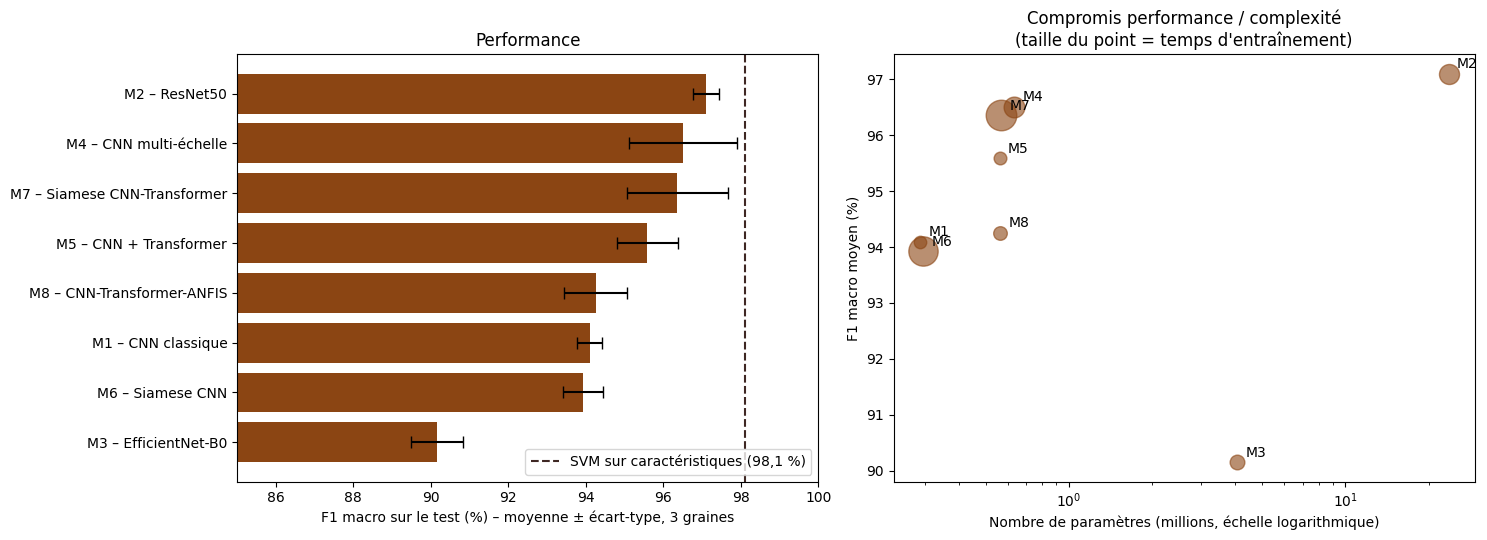

In [5]:
# Performance, Complexité et Temps sur un seul graphique

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Gauche : F1 moyen avec barres d'erreur
ordre = moyennes["F1 (macro)"].sort_values().index
axes[0].barh(ordre, moyennes.loc[ordre, "F1 (macro)"], xerr=ecarts.loc[ordre, "F1 (macro)"],
             capsize=4, color="#8B4513")
axes[0].axvline(98.1, color="#3E2723", linestyle="--", label="SVM sur caractéristiques (98,1 %)")
axes[0].set_xlim(85, 100)
axes[0].set_xlabel("F1 macro sur le test (%) – moyenne ± écart-type, 3 graines")
axes[0].legend(loc="lower right")
axes[0].set_title("Performance")

# Droite : compromis performance / nombre de paramètres (taille des points = temps d'entraînement)
for nom in moyennes.index:
    axes[1].scatter(couts.loc[nom, "Paramètres"] / 1e6, moyennes.loc[nom, "F1 (macro)"],
                    s=couts.loc[nom, "Temps d'entraînement (s)"] / 2, alpha=0.6, color="#8B4513")
    axes[1].annotate(nom.split(" – ")[0], (couts.loc[nom, "Paramètres"] / 1e6, moyennes.loc[nom, "F1 (macro)"]),
                     xytext=(6, 4), textcoords="offset points")
axes[1].set_xscale("log")
axes[1].set_xlabel("Nombre de paramètres (millions, échelle logarithmique)")
axes[1].set_ylabel("F1 macro moyen (%)")
axes[1].set_title("Compromis performance / complexité\n(taille du point = temps d'entraînement)")

plt.tight_layout()
plt.savefig("results/dl/06_comparaison_finale.png", dpi=150)
plt.show()

## Conclusion de l'étape 6

**Classement (F1 macro sur le test, moyenne ± écart-type sur 3 graines) :** M2 – ResNet50 (97,1 ± 0,3) ; M4 – CNN multi-échelle (96,5 ± 1,4) ; M7 – Siamese CNN-Transformer (96,4 ± 1,3) ; M5 – CNN + Transformer (95,6 ± 0,8) ; M8 – CNN-Transformer-ANFIS (94,3 ± 0,8) ; M1 – CNN classique (94,1 ± 0,3) ; M6 – Siamese CNN (93,9 ± 0,5) ; M3 – EfficientNet-B0 (90,2 ± 0,7).

- **Meilleure performance :** ResNet50, le plus précis et le plus stable, mais avec 23,6 millions de paramètres. Ses intervalles chevauchent ceux de M4 et M7 : l'écart n'est pas significatif sur 3 graines.
- **Meilleur compromis performance / complexité :** les architectures légères de 0,6 million de paramètres (M4, M7, M5) atteignent 95,6 à 96,5 % avec 40 fois moins de paramètres que ResNet50. M5 est la plus économique (2,8 minutes d'entraînement) ; M4 et M7 sont plus performantes mais plus instables d'une graine à l'autre (± 1,3 à 1,4).
- **Apport du Transformer :** il améliore le CNN seul dans les deux cadres d'apprentissage (M1 → M5 : +1,5 point ; M6 → M7 : +2,5 points).
- **Apprentissage siamois :** il n'améliore pas la classification par rapport à un apprentissage direct (M6 ≈ M1) et coûte 5 à 6 fois plus de temps d'entraînement, mais offre l'inférence la plus rapide (0,4 ms par image) et des représentations bien structurées (t-SNE).
- **ANFIS :** M8 (94,3 %) est en retrait de M5 (95,6 %) avec le même encodeur, mais sa décision se résume à trois règles floues, une par catégorie : il échange un peu de performance contre de l'interprétabilité.
- **EfficientNet-B0** est dominé : plus de paramètres et de moins bons résultats que les modèles légers, ses caractéristiques ImageNet se transférant mal à des images de 60 × 60 pixels agrandies.
- **Comparaison avec le machine learning :** aucune architecture ne dépasse le SVM sur caractéristiques manuelles (98,1 %). Sur un petit jeu d'images basse résolution, des caractéristiques choisies avec soin (couleur corrigée, fève isolée du fond, texture) restent plus efficaces que l'apprentissage automatique des représentations.
- **Limites :** non-déterminisme du GPU (écarts de 2 points entre deux exécutions de la même graine) ; limites d'époques atteintes par EfficientNet (phase de fine-tuning) et par M6 ; réglages identiques conservés pour toutes les graines afin de garantir la comparabilité.